# Figure 2 — Solar PV exports by destination region (2022–2025)

**Four subplots** (one per year). Monthly export value (billion USD) by destination region. Includes Panels, Cells, and Wafers by default. Data are loaded from the group's public GitHub snapshot. Set `PANELS_ONLY=True` to match the preliminary Panels-only dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
RAW_URL = 'https://raw.githubusercontent.com/Amyzzz17/ZhengWangZhouLi/main/data/Raw/mart_solar_exports_full_release_monthly.csv'
PANELS_ONLY = False
df = pd.read_csv(RAW_URL, low_memory=False)
df['Date'] = pd.to_datetime(df['Date'])
df['Amount (USD)'] = pd.to_numeric(df['Amount (USD)'], errors='coerce')
print(df.shape)

(31254, 13)


In [2]:
selected_products = ['Panels'] if PANELS_ONLY else ['Panels', 'Cells', 'Wafers']
sample = df.loc[(df['Area type'] == 'Country or economy') & df['Date'].dt.year.between(2022, 2025) & df['Commodity type'].isin(selected_products) & df['Region'].notna()].copy()
sample['Year'] = sample['Date'].dt.year
sample['Month'] = sample['Date'].dt.month
monthly_region = sample.groupby(['Year','Month','Region'], as_index=False)['Amount (USD)'].sum(min_count=1)
monthly_region['Value (billion USD)'] = monthly_region['Amount (USD)'] / 1e9
regions = monthly_region.groupby('Region')['Amount (USD)'].sum().sort_values(ascending=False).index.tolist()
print('Region names:', regions)
print('Annual exports in billion USD:')
print(monthly_region.groupby('Year')['Value (billion USD)'].sum().round(2))

Region names: ['Europe', 'Asia', 'Latin America and Caribbean', 'Middle East', 'Africa', 'Oceania', 'North America']
Annual exports in billion USD:
Year
2022    51.91
2023    49.07
2024    32.65
2025    30.11
Name: Value (billion USD), dtype: float64


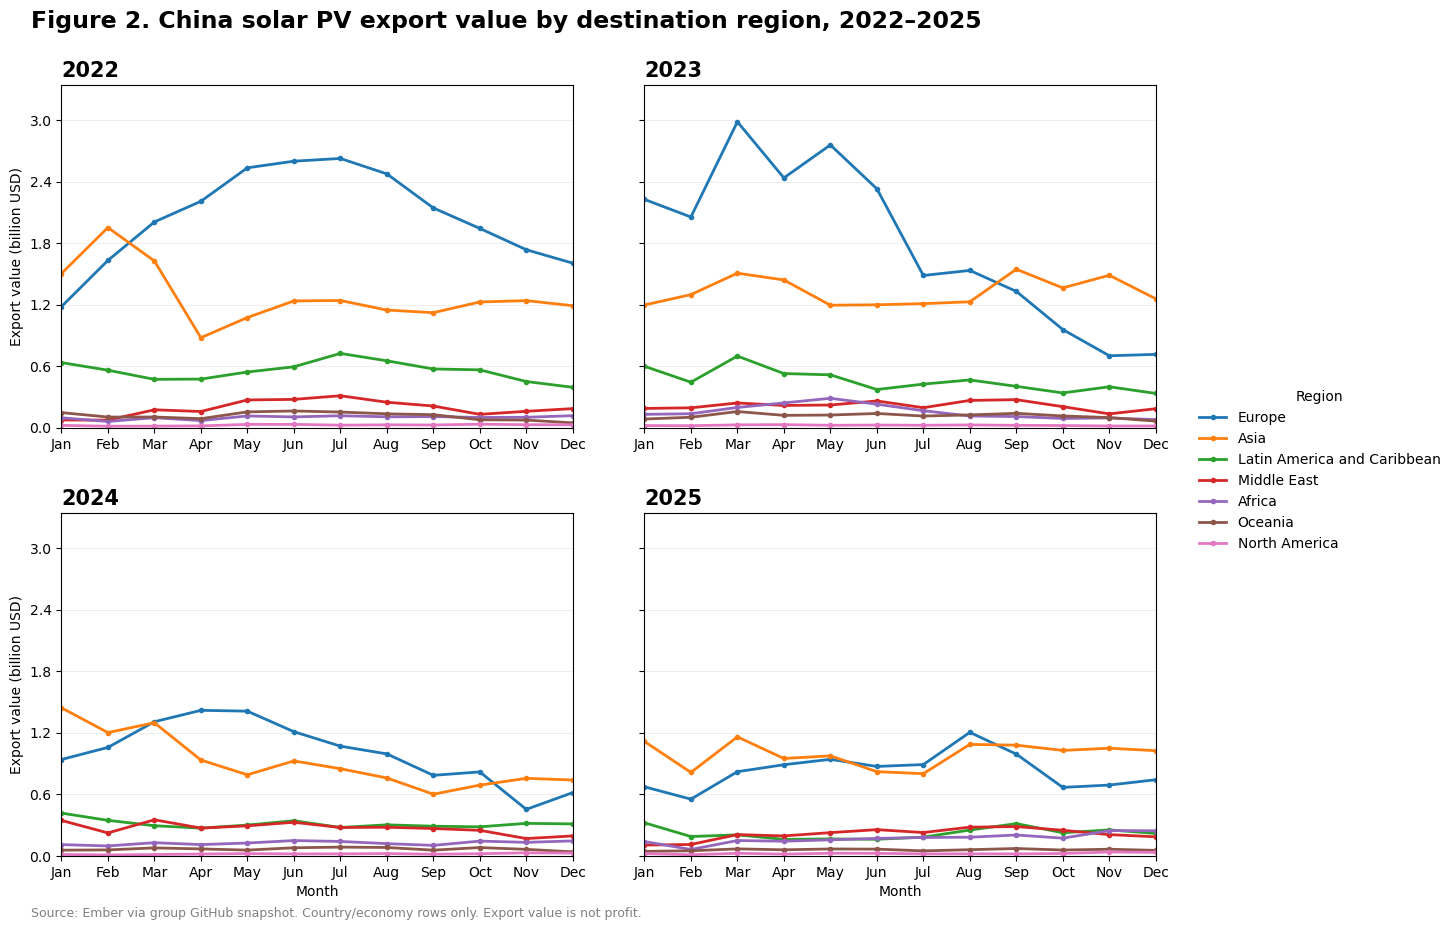

In [3]:
years=[2022,2023,2024,2025]
month_labels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
colors={region:plt.get_cmap('tab10')(i%10) for i,region in enumerate(regions)}
fig,axes=plt.subplots(2,2,figsize=(15.2,9.4),sharex=True,sharey=True)
ymax=monthly_region['Value (billion USD)'].max()
for ax,year in zip(axes.flat,years):
    for region in regions:
        series=(monthly_region[(monthly_region['Year']==year)&(monthly_region['Region']==region)]
               .set_index('Month').reindex(range(1,13)))
        ax.plot(range(1,13),series['Value (billion USD)'],label=region,color=colors[region],marker='o',markersize=3,linewidth=2)
    ax.set_title(str(year),loc='left',fontsize=15,fontweight='bold')
    ax.set_xlim(1,12); ax.set_ylim(0,ymax*1.12)
    ax.set_xticks(range(1,13),month_labels); ax.tick_params(axis='x',labelbottom=True)
    ax.grid(axis='y',alpha=.20); ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
for ax in axes[:,0]: ax.set_ylabel('Export value (billion USD)')
for ax in axes[-1,:]: ax.set_xlabel('Month')
fig.suptitle('Figure 2. China solar PV export value by destination region, 2022–2025',x=.06,y=.99,ha='left',fontweight='bold',fontsize=17)
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='center left',bbox_to_anchor=(.82,.5),frameon=False,title='Region')
fig.text(.06,.025,'Source: Ember via group GitHub snapshot. Country/economy rows only. Export value is not profit.',fontsize=9,color='gray')
fig.subplots_adjust(left=.08,right=.80,top=.91,bottom=.09,wspace=.14,hspace=.25)
fig.savefig('Figure_2_Regional_Export_Value_2022_2025.png',dpi=240,bbox_inches='tight')
fig.savefig('Figure_2_Regional_Export_Value_2022_2025.svg',bbox_inches='tight')
monthly_region.to_csv('Figure_2_Regional_Monthly_USD.csv',index=False)
plt.show()